# Acoustic transducer

Launch shear plate waves in thin-film lithium niobate with an acoustic transducer.

**Question.** An interdigital transducer sits on a 360 nm film of x-cut lithium
niobate: aluminium fingers, alternately signal and ground, at a pitch of 2.2 µm. A
voltage between them strains the crystal through the piezoelectric effect and launches
the fundamental shear plate wave of the film, SH0, both ways along it. What admittance
per metre of aperture does the transducer present? Where does the wave go, and how
much shear strain reaches two waveguide ribs inside the finger set, in which phase?
And which finger pitch makes the transducer radiate most at a chosen frequency?

The stack is the one of Ni, Bhave and Xu (arXiv 2606.05337), who measured an
acousto-optic modulator on it: its S11 dipped to −34.3 dB near 0.84 GHz, and its
voltage-length product was $V_\pi L = 1.004$ V·cm at 0.842 GHz. This page reduces the
transducer to eleven fingers without reflectors and computes the acoustics side: the
admittance, the wave and the strain. The light is outside it.

The chain from voltage to strain is one call and one reading:

1. {py:class}`gfem.Piezoelectric`: the admittance per length between the fingers over a
   band, the clamped capacitance, and the displacement and potential fields, with
   absorbing {term}`damping frames <damping frame>` at the section's edges.
2. {py:func}`gfem.strain`: the engineering strain of the kept displacement at points.

**Assumptions.** The paper states the stack (a 360 nm film etched 180 nm into 2 µm
ribs, 4.7 µm of buried oxide on a silicon handle, 50 nm of aluminium), the 2.2 µm pitch,
the 5.5 µm gaps beside the ribs and the 400 µm aperture. The rest are this page's
choices:

| item | value |
| --- | --- |
| rib sidewalls | 70° (etched ribs lean at 60-75°) |
| finger width | 1.1 µm, half the pitch |
| fingers | 6 signal and 5 ground, no reflector strips |
| silicon handle | 10 µm modelled, clamped at its base, with no potential in it; as a dielectric the admittance moves by 2.3 % |
| air above | 2.5 µm, potential only; doubling it moves the admittance by 0.3 % |
| absorbing edges | damping frames 17.6 µm wide at the sides (four wavelengths of SH0) and 8 µm below, loss factor 1.2 |
| quality factor | $Q_m = 200$ in every material |
| lithium niobate | Warner et al. (1967): stiffness $c^E$, piezoelectric tensor $e$, clamped permittivity $\varepsilon^S$, density 4700 kg/m³ |
| other materials, mesh | oxide, silicon and aluminium from the literature; second-order mesh within 0.4 % of the converged admittance; aluminium resistivity $3.0 \times 10^{-8}$ Ω·m |

The quality factor and the finger metal's constants are inputs the paper does not
measure. The comparison with its measurement closes the section on the device's reflection.

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize
from transducer_section import transducer_section

import gfem

um = 1e-6
tic = time.perf_counter()

## The section

{download}`transducer_section.py` builds the section with netgen, which ships with
NGSolve, writes a gmsh file with the region and line names, and reads it back with
{py:meth}`gfem.Mesh.from_gmsh`, as a mesh of your own would be. The section lies in the
$(x, y)$ plane, $y$ up, $y = 0$ at the top of the film's slab, and the fingers run
along $z$. Its regions are `"ln"` (the film and its ribs), `"box"` (the buried oxide),
`"si"` (the handle), `"signal"` and `"ground"` (the fingers), `"air"`, and one frame
region for each layer, `"ln_frame"`, `"box_frame"` and `"si_frame"`. The line `"bottom"`
is the handle's base.

The crystal is x-cut: its $x$ axis is up, its $y$ axis runs along the film, across the
fingers, and its $z$ axis is along them, reversed. That is the frame of `axes`, whose
rows are the crystal's $x$, $y$ and $z$ in the section's coordinates. The stiffness
$c^E$ and the piezoelectric tensor $e$ are written in the crystal's own frame in
{term}`Voigt order <engineering strain>`, and gfem rotates them.

In [2]:
section = transducer_section()  # 11 fingers at 2.2 um, two ribs, the damping frames

# lithium niobate in the crystal's frame (Warner et al. 1967); GPa and C/m^2
c11, c12, c13, c14, c33, c44 = 203, 53, 75, 9, 245, 60
C_LN = 1e9 * np.array(
    [
        [c11, c12, c13, c14, 0, 0],
        [c12, c11, c13, -c14, 0, 0],
        [c13, c13, c33, 0, 0, 0],
        [c14, -c14, 0, c44, 0, 0],
        [0, 0, 0, 0, c44, c14],
        [0, 0, 0, 0, c14, (c11 - c12) / 2],
    ]
)
e15, e22, e31, e33 = 3.7, 2.5, 0.2, 1.3
E_LN = np.array(
    [
        [0, 0, 0, 0, e15, -e22],
        [-e22, e22, 0, e15, 0, 0],
        [e31, e31, e33, 0, 0, 0],
    ]
)
# silicon is cubic: its 6x6 from c11, c12 and c44
s11, s12, s44 = 165.7e9, 63.9e9, 79.6e9
C_SI = np.zeros((6, 6))
C_SI[:3, :3] = s12
C_SI += np.diag([s11 - s12] * 3 + [s44] * 3)

# x-cut: crystal y along x (the wave), crystal x up, crystal z along -z
AXES = ((0, 1, 0), (1, 0, 0), (0, 0, -1))
Q = dict(mechanical_quality_factor=200.0)
ln = gfem.Material(
    eps_r=(44.0, 44.0, 29.0), axes=AXES, stiffness=C_LN,
    piezoelectric_tensor=E_LN, mass_density=4700.0, **Q,
)  # fmt: skip
sio2 = gfem.Material(
    eps_r=3.9, stiffness=gfem.isotropic_stiffness(73e9, 0.17), mass_density=2203.0, **Q
)
si = gfem.Material(stiffness=C_SI, mass_density=2329.0, **Q)
al = gfem.Material(
    stiffness=gfem.isotropic_stiffness(70e9, 0.35), mass_density=2700.0, **Q
)

# each frame keeps its layer's material; air has no mechanics, silicon no potential
model = gfem.Model(
    section.mesh,
    materials={
        "ln": ln, "ln_frame": ln, "box": sio2, "box_frame": sio2,
        "si": si, "si_frame": si, "signal": al, "ground": al, "air": gfem.Material(),
    },
    excluded={"mechanical": ["air"], "em": ["si", "si_frame"]},
)  # fmt: skip
frame = gfem.DampingFrame(["ln_frame", "box_frame", "si_frame"])  # loss factor 1.2
print(section.mesh)
print(
    f"{section.fingers[0]} signal and {section.fingers[1]} ground fingers, pitch "
    f"{section.pitch / um:.1f} um, ribs {len(section.arms)} at x = "
    + ", ".join(f"{x / um:.1f}" for x in section.arms[:, 0])
    + " um"
)

Mesh(8691 nodes, 17133 triangles, volumes=['si', 'signal', 'si_frame', 'box', 'ground', 'air', 'box_frame', 'ln', 'ln_frame'], surfaces=['bottom'], length_unit='um')
6 signal and 5 ground fingers, pitch 2.2 um, ribs 2 at x = 29.7, 40.7 um


The section, and the film around the ribs:

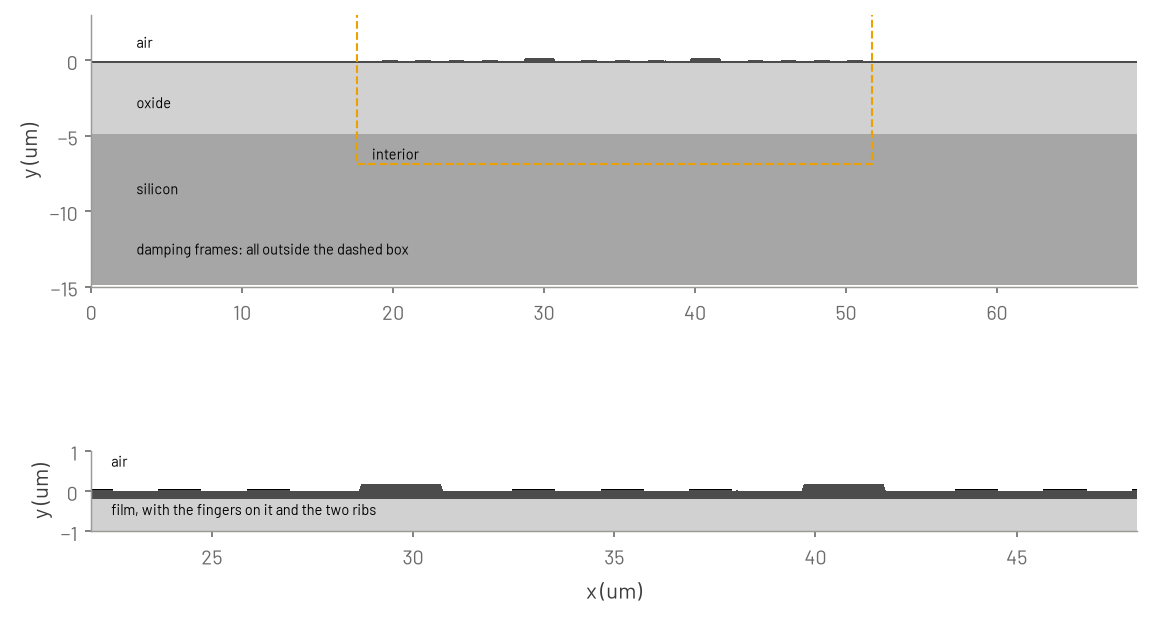

In [3]:
mesh = section.mesh
x, y = np.asarray(mesh.nodes).T / um
level = {"air": 1.0, "box": 0.82, "si": 0.65, "ln": 0.3, "signal": 0.0, "ground": 0.0}
shade = np.empty(len(mesh.volume_elements))  # a grey for each triangle's layer
for name in mesh.volumes:
    shade[mesh.elements(name)] = level[name.removesuffix("_frame")]
inner = ("ln", "box", "si", "signal", "ground")  # the interior, inside the frames
rows = np.concatenate([mesh.elements(name) for name in inner])
y_floor = y[np.unique(mesh.volume_elements[rows])].min()
x_a, x_b = np.array(section.interior) / um

fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(9, 5.4), height_ratios=(2.2, 1))
for ax, (x0, x1, y0, y1) in ((ax_a, (0, 69.3, -15, 3)), (ax_b, (22, 48, -1.0, 1.0))):
    ax.tripcolor(
        x, y, mesh.volume_elements, facecolors=shade, cmap="gray", vmin=0, vmax=1
    )
    ax.add_patch(
        plt.Rectangle(
            (x_a, y_floor), x_b - x_a, 20.0, fill=False, ec="C3", ls="--", lw=1
        )
    )
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect("equal")
    ax.set_ylabel("y (um)")
ax_b.set_xlabel("x (um)")
for text, at in (
    ("air", (3, 1.2)),
    ("oxide", (3, -2.8)),
    ("silicon", (3, -8.5)),
    ("interior", (x_a + 1, -6.2)),
    ("damping frames: all outside the dashed box", (3, -12.5)),
):
    ax_a.text(*at, text, fontsize=7, color="k", va="center")  # fmt: skip
ax_b.text(22.5, 0.6, "air", fontsize=7, color="k")
ax_b.text(
    22.5, -0.6, "film, with the fingers on it and the two ribs", fontsize=7, color="k"
);

The handle's electrical model is the model's own: `"si"` and `"si_frame"` are left out
of the electromagnetic domain, so the handle carries no potential. The mechanical domain
is every region but the air: each needs a stiffness and a density, and the fingers carry
both, so they load the film as mass and stiffness.

## Admittance and clamped capacitance

{py:class}`gfem.Piezoelectric` puts 1 V on the signal fingers and 0 V on the ground,
over a list of frequencies. The handle's base is a clamped line (zero displacement),
every other edge is free, and the damping frame absorbs the waves that reach the
section's edges. `keep_fields=True` keeps the displacement and potential at every
frequency, about 40 MB here. The sweep covers the transducer's band, 0.80 to 0.92 GHz
in 5 MHz steps: 25 factorizations of 100 000 unknowns.

In [4]:
FREQUENCIES = np.arange(0.80e9, 0.9201e9, 5e6)
sweep = gfem.Piezoelectric(
    FREQUENCIES,
    terminals={"signal": "signal"},
    ground="ground",
    clamped="bottom",
    damping_frame=frame,
    keep_fields=True,
)
res = gfem.solve(model, sweep)
print(res)

PiezoelectricResult(terminals=['signal'], 25 frequencies 800-920 MHz, clamped capacitance per length in pF/m:
  signal:      686.8)


`admittance_per_length` is $Y'(f)$ in S/m, the current into the signal fingers per volt
and per metre of aperture; the transducer's own admittance is $Y' W$ for an aperture
$W$. `clamped_capacitance_per_length` is $C_0'$, the capacitance with the crystal held
still, in F/m. The radiation conductance $G' = \mathrm{Re}\,Y'$ is the power the
transducer takes, $\tfrac12 G' |V|^2$ per metre of aperture, all of it radiated or lost
in the frames. It must be positive at every frequency, and it peaks at the
{term}`synchronous frequency` $v / (2p)$, with $v$ the wave's speed under the fingers and
$p$ the pitch. The imaginary part is mostly the capacitance, $\omega C_0'$.

In [5]:
y = np.asarray(res.admittance_per_length)[:, 0, 0]  # S/m
c0 = float(res.clamped_capacitance_per_length[0, 0])  # F/m
f_ghz = res.frequency / 1e9
omega = 2 * np.pi * res.frequency


def vertex(f, values, i):
    # The extremum of the parabola through samples i - 1, i, i + 1 (Hz).
    a, b, _ = np.polyfit(f[i - 1 : i + 2] - f[i], values[i - 1 : i + 2], 2)
    return f[i] - b / (2 * a)


i_peak = int(np.argmax(y.real))
f_peak = vertex(res.frequency, y.real, i_peak)
v_wave = 2 * section.pitch * f_peak  # the wave's speed under the fingers, m/s
print(f"smallest Re Y' = {y.real.min():.3f} S/m, positive at all {len(y)} frequencies")
print(f"C0' = {1e12 * c0:.1f} pF/m")
print(f"Re Y' peaks at {f_peak / 1e9:.4f} GHz: v = 2 p f = {v_wave / 1e3:.2f} km/s")
edge = [0, -1]
print(
    "Im Y' / (omega C0') at the band's edges:",
    np.round(y.imag[edge] / (omega[edge] * c0), 2),
)

smallest Re Y' = 0.306 S/m, positive at all 25 frequencies
C0' = 686.8 pF/m
Re Y' peaks at 0.8646 GHz: v = 2 p f = 3.80 km/s
Im Y' / (omega C0') at the band's edges: [1.4  1.19]


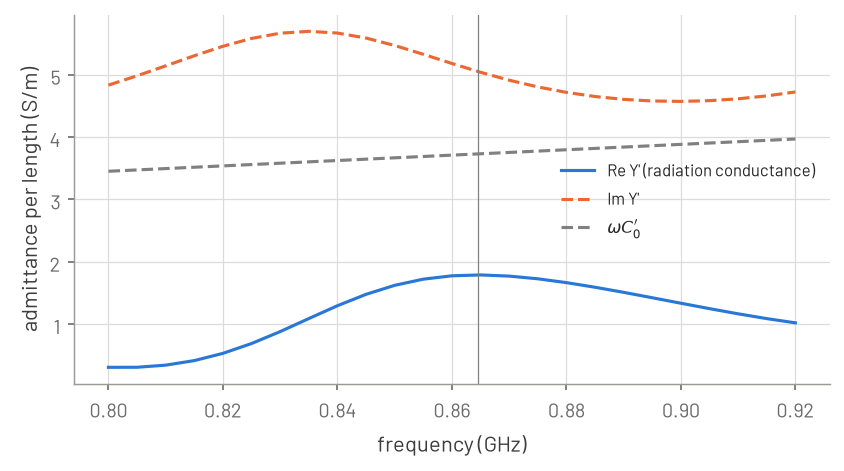

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(f_ghz, y.real, label="Re Y' (radiation conductance)")
ax.plot(f_ghz, y.imag, label="Im Y'")
ax.plot(f_ghz, omega * c0, ls="--", color="gray", label=r"$\omega C_0'$")
ax.axvline(f_peak / 1e9, color="gray", lw=0.6)
ax.set_xlabel("frequency (GHz)")
ax.set_ylabel("admittance per length (S/m)")
ax.legend(fontsize=8);

The conductance rises from 0.3 S/m at 0.80 GHz to a peak of 1.8 S/m at 0.865 GHz and
falls to 1.0 S/m at 0.92 GHz: the fingers radiate most when each half-wavelength fits
one pitch, which gives the SH0 speed under the fingers, 3.80 km/s. The susceptance stays
above $\omega C_0'$, by 40 % at the band's low edge and 19 % at its high one: the free
crystal stores more charge per volt than the clamped one, by a factor $1 + K^2$, and the
resonance adds its own reactance.

The series resonance $f_s$ is the maximum of $|Y'|$ and the parallel $f_p$ its minimum
above it, with $k^2_\mathrm{eff} = (f_p^2 - f_s^2) / f_p^2$. On a short, radiating
transducer this describes the transducer, with its eleven fingers and its frames, and not
the crystal's own coupling.

In [7]:
mag = np.abs(y)
i_s = int(np.argmax(mag))
i_p = i_s + int(np.argmin(mag[i_s:]))
f_s, f_p = vertex(res.frequency, mag, i_s), vertex(res.frequency, mag, i_p)
k2_eff = (f_p**2 - f_s**2) / f_p**2
print(f"f_s = {f_s / 1e9:.4f} GHz, f_p = {f_p / 1e9:.4f} GHz, k2_eff = {k2_eff:.3f}")

f_s = 0.8390 GHz, f_p = 0.9056 GHz, k2_eff = 0.142


## The wave

With the fields kept, the displacement is a map of three components in m per volt,
`res.displacement(f)["x"]`, `["y"]` and `["z"]`. The wave of this shear plate mode is
polarized along the fingers, $u_z$. Its real part and amplitude along the film's
mid-depth at the conductance peak show the wave leaving both ways and dying in the
frames, whose extent is shaded.

|u_z| falls across the frames by 29 on the left and 33 on the right


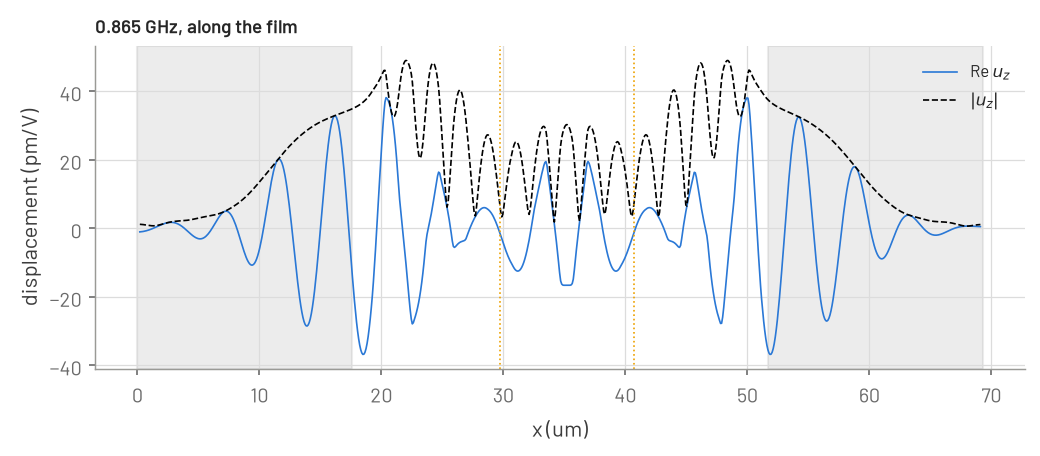

In [8]:
f_wave = FREQUENCIES[
    np.argmin(np.abs(FREQUENCIES - f_peak))
]  # the grid frequency nearest the peak
x_end = section.interior[0] + section.interior[1]
xs = np.linspace(0.2 * um, x_end - 0.2 * um, 800)
line = np.column_stack([xs, np.full_like(xs, -0.09 * um)])  # the film's mid-depth
u_z = np.asarray(res.displacement(f_wave)["z"].at(line))  # m / V
amplitude = np.abs(u_z)
edge_in = [np.argmin(np.abs(xs - x)) for x in section.interior]
left = amplitude[edge_in[0]] / amplitude[0]
print(
    f"|u_z| falls across the frames by {left:.0f} on the left "
    f"and {amplitude[edge_in[1]] / amplitude[-1]:.0f} on the right"
)

fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(xs / um, 1e12 * u_z.real, lw=0.8, label=r"Re $u_z$")
ax.plot(xs / um, 1e12 * np.abs(u_z), color="k", lw=0.8, ls="--", label=r"$|u_z|$")
ax.axvspan(0, section.interior[0] / um, color="gray", alpha=0.15)
ax.axvspan(section.interior[1] / um, x_end / um, color="gray", alpha=0.15)
for xa in section.arms[:, 0]:
    ax.axvline(xa / um, color="C3", lw=0.8, ls=":")
ax.set_xlabel("x (um)")
ax.set_ylabel("displacement (pm/V)")
ax.set_title(f"{f_wave / 1e9:.3f} GHz, along the film", fontsize=9)
ax.legend(fontsize=8, loc="upper right");

The wave grows towards the ends of the finger set, where every finger has added its
share, and runs out of it in both directions with a wavelength of $2p = 4.4$ µm. The
frames take its amplitude down by the factor printed above, so little returns to the
fingers.

## The strain at the arms

The two ribs sit in the 5.5 µm gaps beside which two fingers are left out. They are
five pitches apart, an odd number of half-wavelengths, so the wave pulls on one arm as
it pushes on the other: the strain is in opposite phase there. {py:func}`gfem.strain`
reads it. It takes the kept displacement and points, and returns the six strain
components at each, per volt, in {term}`Voigt order <engineering strain>` with
engineering shear: $S = (S_{xx}, S_{yy}, S_{zz}, S_{yz}, S_{xz}, S_{xy})$. The shear
wave carries $S_{xz} = \partial_x u_z$, the fifth entry.

In [9]:
s_xz = np.array([np.asarray(gfem.strain(res.displacement(f), section.arms))[:, 4]
                 for f in res.frequency])  # 1/V, (frequencies, arms)  # fmt: skip
phase = np.degrees(np.angle(s_xz[:, 1] / s_xz[:, 0]))
i_w = int(np.argmin(np.abs(res.frequency - f_wave)))
a1, a2 = np.abs(s_xz[i_w])
print(f"|S_xz| at {f_wave / 1e9:.3f} GHz: {a1:.2e} and {a2:.2e} per volt")
lo, hi = np.abs(phase).min(), np.abs(phase).max()
print(f"phase between the arms: {lo:.1f} to {hi:.1f} degrees")

|S_xz| at 0.865 GHz: 3.43e-05 and 3.43e-05 per volt
phase between the arms: 179.9 to 180.0 degrees


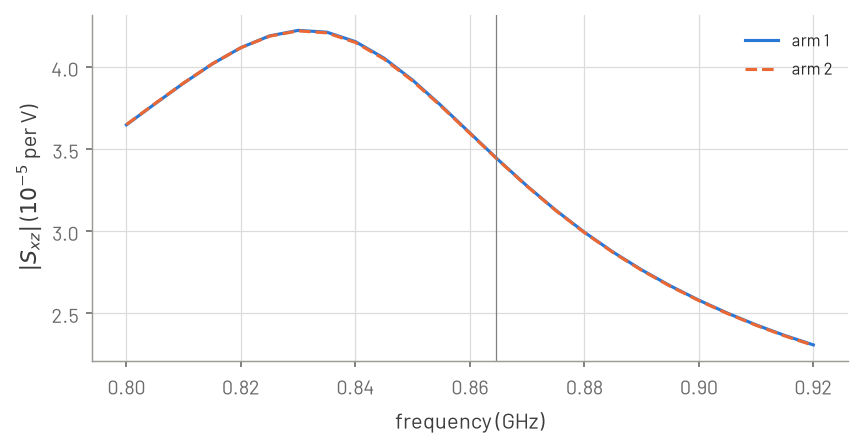

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
for k, label in enumerate(("arm 1", "arm 2")):
    ax.plot(f_ghz, 1e5 * np.abs(s_xz[:, k]), label=label, ls="-" if k == 0 else "--")
ax.axvline(f_peak / 1e9, color="gray", lw=0.6)
ax.set_xlabel("frequency (GHz)")
ax.set_ylabel(r"$|S_{xz}|$ ($10^{-5}$ per V)")
ax.legend(fontsize=8);

The strain amplitudes are the same at both arms, $3.4 \times 10^{-5}$ per volt at the
peak, and the phase between them is 180° at every frequency: the push-pull a
modulator's arms would use, set by the geometry and not by the frequency. This page
stops at the strain.

## The device's reflection

A circuit sees the transducer through its aperture $W$ and the resistance of its
fingers. `res.network_parameters(aperture, series_resistance=...)` turns $Y'$ into
$Y = W Y'$, adds $R_s$ in series, and returns the scattering parameters on 50 Ω: for
one terminal $S_{11} = (Z_L - Z_0) / (Z_L + Z_0)$ with $Z_L = 1/Y + R_s$. The aperture
is 400 µm, and each finger, fed from one end, has the resistance
$R_f = \rho_\mathrm{Al} W / (w_f t)$, so the fingers in parallel give
$R_s = \tfrac{R_f}{3} (1/N_S + 1/N_G)$. The resistance is the page's JAX, because it
does not change the field solve ({doc}`../recipes/piezoelectric-admittance`).

In [11]:
RHO_AL, W_FINGER, T_FINGER = 3.0e-8, 1.1e-6, 50e-9  # ohm m, m, m


def r_s(aperture):
    # The fingers' series resistance, ohm: each finger fed from one end.
    n_signal, n_ground = section.fingers
    r_finger = RHO_AL * aperture / (W_FINGER * T_FINGER)
    return r_finger / 3 * (1 / n_signal + 1 / n_ground)


APERTURE = 400e-6  # m
net = res.network_parameters(aperture=APERTURE, series_resistance=r_s(APERTURE))
s11_db = np.asarray(net.db("signal", "signal"))
z_load = 1 / (APERTURE * y) + float(r_s(APERTURE))  # ohm
print(f"R_s = {float(r_s(APERTURE)):.1f} ohm")
z = z_load[i_w]
print(
    f"at {f_wave / 1e9:.3f} GHz: Z = {z.real:.1f} {z.imag:+.1f}i ohm, "
    f"S11 = {s11_db[i_w]:.2f} dB"
)
print(f"S11 between {s11_db.min():.2f} and {s11_db.max():.2f} dB over the band")

R_s = 26.7 ohm
at 0.865 GHz: Z = 183.0 -440.5i ohm, S11 = -0.69 dB
S11 between -0.69 and -0.19 dB over the band


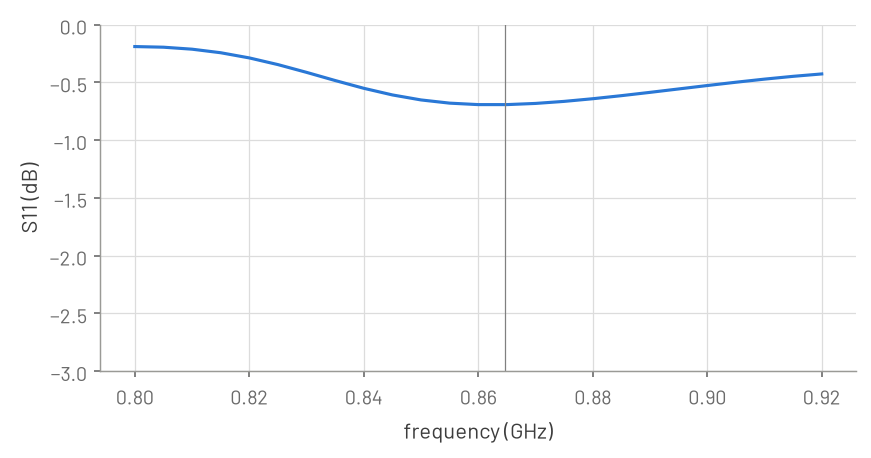

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 3.0))
ax.plot(f_ghz, s11_db)
ax.axvline(f_peak / 1e9, color="gray", lw=0.6)
ax.set_xlabel("frequency (GHz)")
ax.set_ylabel("S11 (dB)")
ax.set_ylim(-3, 0);

The short transducer is mostly a capacitor: at its conductance peak $Z$ is
$183 - 440i$ Ω, a large negative reactance, and $S_{11}$ stays between −0.7 and −0.2 dB
over the band. The radiation conductance grows as $N^2$ in the number of fingers and the
capacitance only as $N$, so a longer transducer matches; no pitch matches this one. The
paper's transducer has more fingers and reflectors, and its S11 dips to −34.3 dB near
0.84 GHz.

**The full-size section, an observation.** With 20 signal and 19 ground fingers and 40
grounded strips on each side (assumed counts), the same section has 1.14 million unknowns
and takes 4 s and 5.2 GiB per frequency on 32 cores. At 0.8597 GHz it gives
$Z = 41.5 + 0.7i$ Ω, and with $R_s = 7.5$ Ω an S11 dip of about −38 dB near 0.8596 GHz,
about 2 % above the measured 0.84 GHz. A cross-section has no finger ends, busbars or
diffraction across the aperture, and the constants, sidewall angle and finger width are
assumed: the page does not apportion the difference and asserts no band against the
measurement ({doc}`../verification`).

## The pitch's exact derivative

The radiation conductance depends on the pitch through the geometry, and a pitch that
the design loop can move needs its derivative. A mesh made for one pitch serves a
nearby one if its nodes move, without a remesh: the section's nodes are a JAX function
of a stretch $\sigma$ of the pitch, and {py:meth}`gfem.Mesh.with_nodes` puts them on the
mesh. The map scales everything between the two lateral frames about the left frame's
inner edge, which carries the fingers and the ribs with it, and translates the right
frame rigidly, so the damping stays what it was. The arms stay an odd number of
half-wavelengths apart.

The objective is the conductance at 0.9 GHz, $\mathrm{Re}\,Y'(0.9\ \mathrm{GHz})$, and
$\sigma$ is a JAX scalar, so `jax.value_and_grad` returns its value and exact derivative
from one solve and one pass over the nodes. The solve is an ordinary
{py:func}`gfem.solve`: the node map is the only JAX in the loop.

In [13]:
x_left, x_right = section.interior  # the span between the lateral frames, m
nodes0 = jnp.asarray(section.mesh.nodes)
one_frequency = gfem.Piezoelectric(
    0.9e9, terminals={"signal": "signal"}, ground="ground", clamped="bottom",
    damping_frame=frame,
)  # fmt: skip


def stretch(nodes, sigma):
    # The pitch times sigma: scale the interior about the left frame's inner edge,
    # translate the right frame rigidly.
    x = nodes[:, 0]
    inside = jnp.clip(x, x_left, x_right)
    return nodes.at[:, 0].set(x - inside + x_left + sigma * (inside - x_left))


def conductance(sigma):
    # Re Y' at 0.9 GHz with every pitch scaled by sigma, S/m.
    moved = model.replace(mesh=section.mesh.with_nodes(stretch(nodes0, sigma)))
    return jnp.real(gfem.solve(moved, one_frequency).admittance_per_length[0, 0, 0])


g_start, dg_start = jax.value_and_grad(conductance)(1.0)
h = 1e-4  # the relative step
dg_fd = (conductance(1 + h) - conductance(1 - h)) / (2 * h)
fd_error = abs(float(dg_start) / float(dg_fd) - 1)
print(
    f"Re Y' at 0.9 GHz = {float(g_start):.4f} S/m, d/dsigma = {float(dg_start):.4f} S/m"
)
print(
    f"central difference at h = {h:g}: {float(dg_fd):.4f} S/m, "
    f"relative difference {fd_error:.1e}"
)

Re Y' at 0.9 GHz = 1.3349 S/m, d/dsigma = -18.5072 S/m
central difference at h = 0.0001: -18.5071 S/m, relative difference 1.0e-06


The derivative is the one a reader checks with two forward solves: a central difference
at a relative step of $10^{-4}$, 0.22 nm of pitch, agrees to the relative difference
printed above. It is exact; the check bounds the truncation of the difference, which falls
as $h^2$. A longer transducer, or one between reflectors, resonates more sharply: shrink
the step, or use fourth-order differences, until the difference stops changing.

## Designing for 0.9 GHz

The transducer radiates most at 0.865 GHz, and the peak frequency scales as $1/p$. To
move it to 0.9 GHz is a one-parameter design: maximise the conductance at 0.9 GHz over
$\sigma$. The main lobe is about 0.16 GHz wide, so the start at $\sigma = 1$ is inside
it and the objective is smooth, with a single maximum. `scipy.optimize.minimize` with
L-BFGS-B takes the value and the exact derivative together (`jac=True`) and the bounds
of the stretch.

In [14]:
def negative(s):
    value, grad = jax.value_and_grad(conductance)(float(s[0]))
    return -float(value), -np.asarray([grad])


best = minimize(negative, [1.0], jac=True, method="L-BFGS-B", bounds=[(0.9, 1.1)],
                options={"maxiter": 10})  # fmt: skip
sigma_opt = float(best.x[0])
g_opt = -best.fun
print(
    f"L-BFGS-B: success {best.success}, {best.nfev} evaluations, "
    f"sigma = {sigma_opt:.4f}"
)
print(f"pitch {section.pitch / um:.3f} um -> {sigma_opt * section.pitch / um:.3f} um")
print(f"Re Y' at 0.9 GHz: {float(g_start):.3f} -> {g_opt:.3f} S/m")

L-BFGS-B: success True, 9 evaluations, sigma = 0.9537
pitch 2.200 um -> 2.098 um
Re Y' at 0.9 GHz: 1.335 -> 1.942 S/m


A second sweep at the optimum, on the moved mesh, shows where the conductance now
peaks. It runs on 7 frequencies at 20 MHz.

In [15]:
moved = model.replace(mesh=section.mesh.with_nodes(stretch(nodes0, sigma_opt)))
sweep_opt = gfem.Piezoelectric(
    np.arange(0.80e9, 0.9201e9, 20e6),
    terminals={"signal": "signal"}, ground="ground", clamped="bottom",
    damping_frame=frame,
)  # fmt: skip
res_opt = gfem.solve(moved, sweep_opt)
y_opt = np.asarray(res_opt.admittance_per_length)[:, 0, 0]
i_opt = int(np.argmax(y_opt.real))
f_opt = vertex(res_opt.frequency, y_opt.real, i_opt)
pitch_opt = sigma_opt * section.pitch
print(f"Re Y' peaks at {f_opt / 1e9:.4f} GHz after, {f_peak / 1e9:.4f} GHz before")
print(
    f"f_peak * p = {f_opt * pitch_opt:.1f} m/s after, "
    f"{f_peak * section.pitch:.1f} m/s before"
)

Re Y' peaks at 0.9057 GHz after, 0.8646 GHz before
f_peak * p = 1900.2 m/s after, 1902.2 m/s before


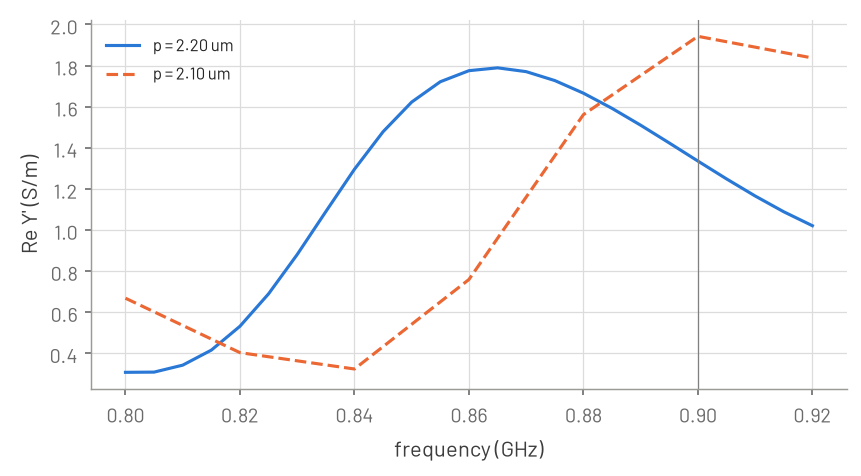

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(f_ghz, y.real, label=f"p = {section.pitch / um:.2f} um")
ax.plot(res_opt.frequency / 1e9, y_opt.real, "--", label=f"p = {pitch_opt / um:.2f} um")
ax.axvline(0.9, color="gray", lw=0.6)
ax.set_xlabel("frequency (GHz)")
ax.set_ylabel("Re Y' (S/m)")
ax.legend(fontsize=8);

The conductance at 0.9 GHz rises from 1.34 to 1.94 S/m in nine evaluations, at a stretch
of 0.954: the pitch goes from 2.200 to 2.098 µm, and the peak from 0.865 to 0.906 GHz. It
lands above 0.9 GHz because the objective is the conductance at 0.9 GHz, not the position
of the peak. The product of the peak frequency and the pitch, half the wave's speed under
the fingers, stays at 1.90 km/s to 0.1 %: the pitch moves the band by the geometry alone.
The ribs moved with the fingers, so the arms stay five pitches apart.

## Checks

| check | value | asserted |
| --- | --- | --- |
| conductance positive at every frequency, peak | 1.8 S/m at 0.865 GHz | peak between 0.855 and 0.875 GHz |
| strain at the two arms | phase 180° | in opposite phase to 1° |
| clamped capacitance | positive | positive |
| pitch derivative against a central difference | printed above | to $10^{-5}$ |
| optimizer | success, pitch 2.098 µm | pitch between 2.05 and 2.17 µm; conductance above the start's |
| peak frequency times pitch | 1.90 km/s | unchanged to 1 % |

## Limits

- **A cross-section.** The section is uniform along the fingers: there are no finger
  ends, busbars or diffraction across the aperture, and the admittance scales with the
  aperture exactly.
- **Absorbing edges are damping frames,** not a perfectly matched layer. Their width is
  four wavelengths of SH0 for a reflection under $10^{-3}$, and the handle's frame below
  is thin in wavelengths: it reflects bulk waves, which carry little power here.
- **Losses are lumped in $Q_m$.** Dielectric loss is not read, and the fingers'
  resistance is a circuit element $R_s$, not part of the field solve.
- **No reflector strips on the page.** The full transducer is an observation, not a run.
- **The light is not computed here.** The index change and the modulator's $V_\pi L$,
  measured at 1.004 V·cm at 0.842 GHz, are the {doc}`acousto-optic page <acousto-optic>`'s.
- **The derivative is of the conductance at a frequency,** with the rib width scaling
  with the pitch. The frequencies, the terminals, the clamped lines and the damping frame
  are not differentiable.

## Next

- {doc}`../recipes/piezoelectric-admittance`: the admittance, the damping frames, the
  network parameters and the strain, step by step.
- {doc}`../recipes/piezoelectric-gradient`: the gradients with respect to the material
  tensors, a node map of your own and the readings of the fields.
- {doc}`modulator`: the same crystal's electro-optic side, with the field as the drive.
- {doc}`../recipes/2d-models`: what a 2D section reads and what it refuses.
- {py:mod}`gfem.conventions`: the stress-charge relations, the Voigt order and the
  sign of the loss.

In [17]:
np.testing.assert_array_less(0.0, y.real)
np.testing.assert_array_less(0.855, f_peak / 1e9)
np.testing.assert_array_less(f_peak / 1e9, 0.875)
np.testing.assert_allclose(np.abs(phase), 180.0, atol=1.0)
np.testing.assert_array_less(0.0, c0)
np.testing.assert_array_less(fd_error, 1e-5)
np.testing.assert_equal(best.success, True, err_msg=best.message)
np.testing.assert_array_less(2.05, pitch_opt / um)
np.testing.assert_array_less(pitch_opt / um, 2.17)
np.testing.assert_array_less(float(g_start), g_opt)
np.testing.assert_allclose(f_opt * pitch_opt, f_peak * section.pitch, rtol=0.01)
print(f"page run in {time.perf_counter() - tic:.0f} s")

page run in 296 s
